Importing the libraries

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
# loading the dataset
df = pd.read_csv('malazan_commander_stats.csv')
df.head()

,Commander,Faction,Campaigns,Battles_Won,Battles_Lost,Magic_Support_Level,Avg_Casualty_Rate_%
0,Dujek Onearm,Malazan Army,18,15,3,Medium,22
1,Whiskeyjack,Bridgeburners,14,13,1,High,9
2,Tayschrenn,High Mage Corps,9,8,1,Very High,15
3,Tavore Paran,Bonehunters,6,5,1,Low,33
4,Adjunct Lorn,Claw,5,4,1,Medium,26


Creating a bar chart showing Battles_won per commander
X-axis = Commander
y-axis =  Battles_won 


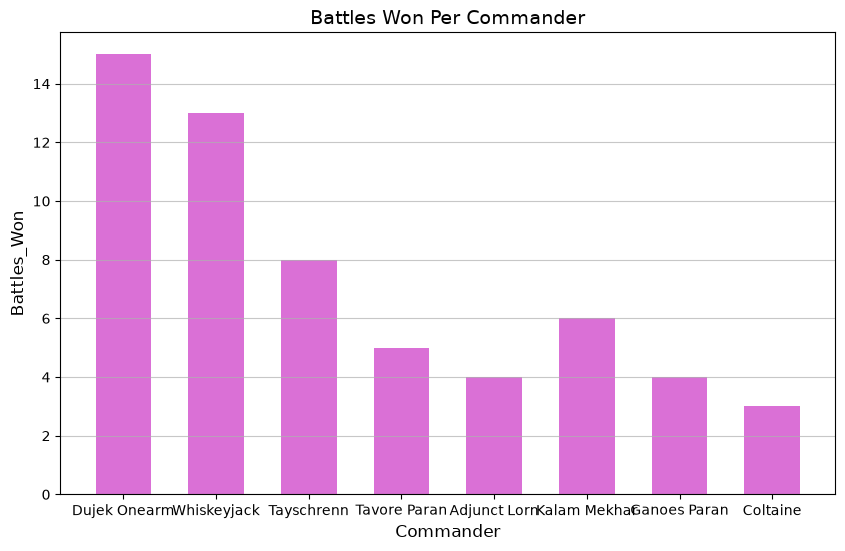

In [14]:
#setting the plot size
plt.figure(figsize=(10,6))
# width give the width to the bar
plt.bar(df['Commander'],df['Battles_Won'],color='orchid',width=0.6)
plt.title("Battles Won Per Commander",fontsize=14)
plt.xlabel("Commander",fontsize=12)
plt.ylabel("Battles_Won",fontsize=12)
# axis y draws horizontal lines in grid and alpha decides transparency of the grid lines
plt.grid(axis='y',linestyle='-',alpha=0.7)
plt.show()



Plotting histogram for Avg_Casuality_Rate_%.
Commander with highest casuality rate and strategic inference

In [28]:
# sorting th e values of avg casuality and displaying only commander and average casuality 
df_sorted = (df.sort_values("Avg_Casualty_Rate_%")[["Commander", "Avg_Casualty_Rate_%"]]).reset_index(drop=True)
print(df_sorted)

      Commander  Avg_Casualty_Rate_%
0  Kalam Mekhar                    5
1   Whiskeyjack                    9
2  Ganoes Paran                   11
3    Tayschrenn                   15
4  Dujek Onearm                   22
5  Adjunct Lorn                   26
6  Tavore Paran                   33
7      Coltaine                   42


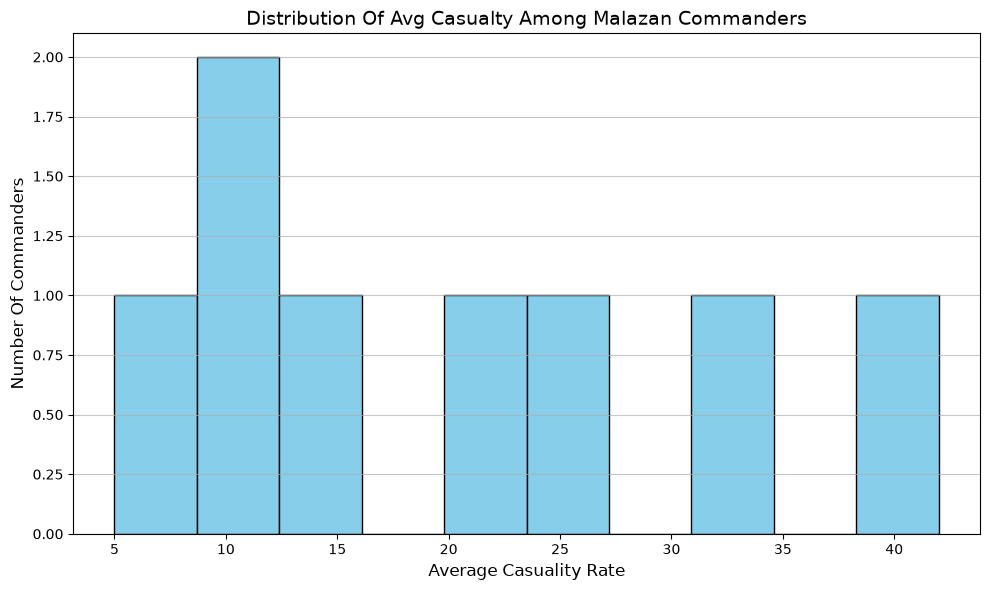

In [18]:
plt.figure(figsize=(10,6))
# edgecolor draws edges to bars 
plt.hist(df["Avg_Casualty_Rate_%"],bins=10,color='skyblue',edgecolor='black')
plt.title("Distribution Of Avg Casualty Among Malazan Commanders",fontsize=14)
plt.xlabel("Average Casuality Rate",fontsize=12)
plt.ylabel("Number Of Commanders",fontsize=12)
plt.grid(axis='y',linestyle='-',alpha=0.7)
plt.tight_layout()
plt.show()



x-axis is the casuality rate bucket and y-axis is the number of commanders per bucket
The non empty bin at the extreme right fall at 42 meaning Coltaine is the commander of highest risk.

Strategic Inference:
The height of most of the bars is at 1 meaning 1 commander each.
The height of the bin between 8 and 12 has height 2 so whiskey Jack and Granoes Paran fall into it.
There are gaps in between the bins,meaning no commanders fall into them.
Most commanders cluster below 26% bin.
Coltaine and Tavore paran are the two outliers at 33 and 42 that is more casuality rates than the others.
Kalam Mekar is the safest with average casuality at 5%





Scatter plot by Faction
Campaigns x and Battle_won y


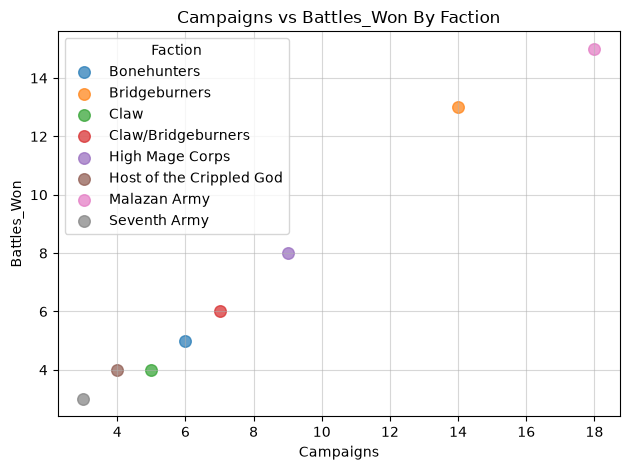

In [22]:
#split the datset into separate groups of Faction with unque values
for Faction,group in df.groupby('Faction'):
    plt.scatter(
        group["Campaigns"],
        group["Battles_Won"],
        label=Faction,# gives label to each dot in the legend
        s=70,# size of the dots
        alpha=0.7
    )
plt.title("Campaigns vs Battles_Won By Faction")
plt.xlabel("Campaigns")
plt.ylabel("Battles_Won")
# loc places the legend box on upper left
plt.legend(title='Faction', loc='upper left')
plt.grid(True,linestyle='-',alpha=0.5)
plt.tight_layout()
plt.show()
        
        
        
    

The scatter plot shows strong positive correlation between campaigns and Battles_Won

Box plot of Avg_Casualty_Rate_%
comment on spread and risks of different commanders

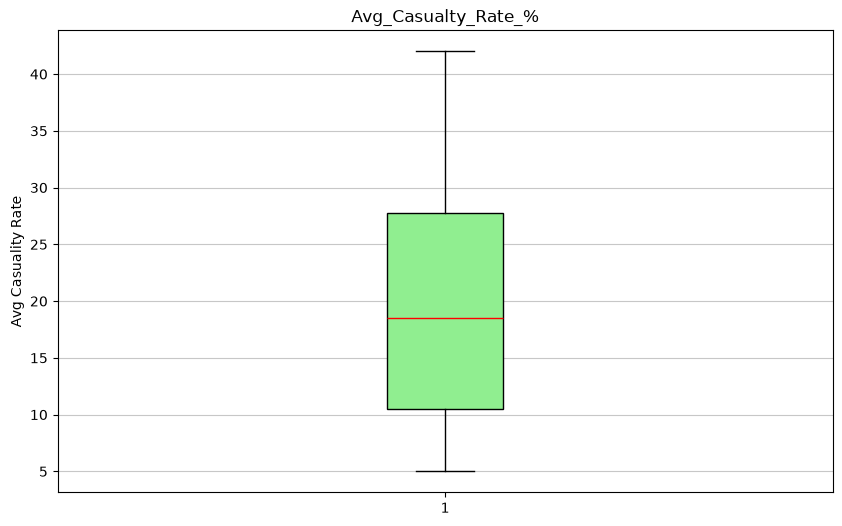

In [23]:
plt.figure(figsize=(10,6))
plt.boxplot(df["Avg_Casualty_Rate_%"],patch_artist=True,boxprops=dict(facecolor='lightgreen'),
            medianprops=dict(color='red'))
plt.title("Avg_Casualty_Rate_%")
plt.ylabel("Avg Casuality Rate")
plt.grid(True,linestyle='-',alpha=0.7,axis='y')
plt.show()




Risk:
Upper whisker is at 42 so Coltaine is at highest casuality risk.
The lower whisker is at 5 so Kalam is the safest with least risk of casuality
The median is at 18.5 so half the commanders lost lesser than 18.5% of their forces.
Spread:
Q1 is at 10.5 so 25%  of commanders are seated below this.
Q3 is at 27.5 so 25% of commanders are seated above this.
Taller box shows that the commanders are spread out.
The upper whisker is longer than the lower, so the graph is skewed.



Line chart showing campaigns per commander

In [25]:
df_sorted = df.sort_values("Campaigns").reset_index(drop=True)
print(df_sorted)

      Commander                   Faction  Campaigns  Battles_Won  \
0      Coltaine              Seventh Army          3            3   
1  Ganoes Paran  Host of the Crippled God          4            4   
2  Adjunct Lorn                      Claw          5            4   
3  Tavore Paran               Bonehunters          6            5   
4  Kalam Mekhar        Claw/Bridgeburners          7            6   
5    Tayschrenn           High Mage Corps          9            8   
6   Whiskeyjack             Bridgeburners         14           13   
7  Dujek Onearm              Malazan Army         18           15   

   Battles_Lost Magic_Support_Level  Avg_Casualty_Rate_%  
0             0                 Low                   42  
1             0                High                   11  
2             1              Medium                   26  
3             1                 Low                   33  
4             1                 NaN                    5  
5             1         

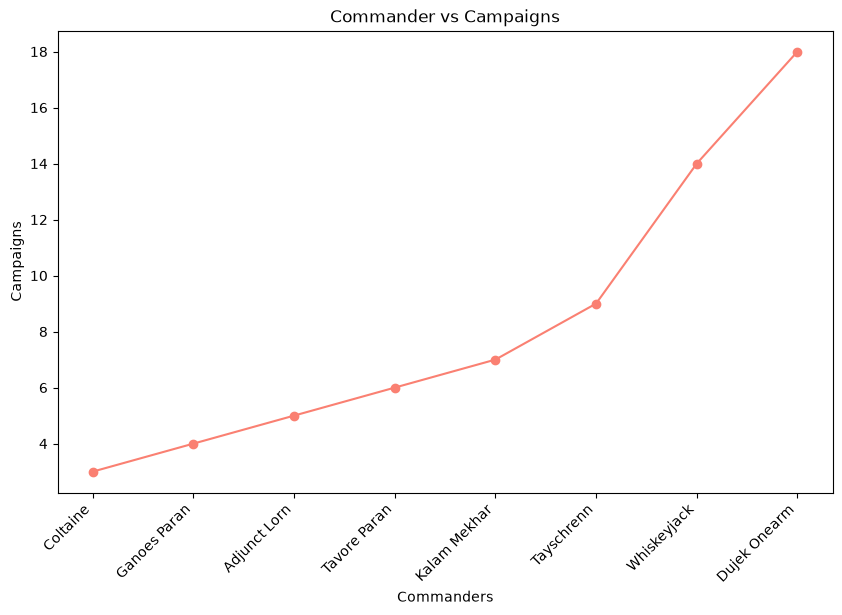

In [27]:
plt.figure(figsize=(10,6))
plt.plot(df_sorted["Commander"],df_sorted["Campaigns"],color='salmon',
         marker='o',linestyle='-',markersize=6)
plt.title("Commander vs Campaigns")
plt.xlabel("Commanders")
plt.ylabel("Campaigns")
plt.xticks(rotation=45,ha='right')
plt.show()